# Modèles Génératifs avec PyTorch — Première Partie
**TP : IA Générative Multi-Modale**

Plan :
0. Projet Python avec UV + dépendances
1. Chargement du dataset MNIST
2. Modèle discriminatif (classifieur)
3. Auto-encodeur simple
4. Variational Autoencoder (VAE)

## 0. Préparation de l'environnement

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.15.0+cpu
Device : cpu


## 1. Chargement du dataset MNIST

MNIST : 70 000 images de chiffres manuscrits (60 000 train / 10 000 test), en niveaux de gris, 28×28 pixels, 10 classes (0–9).

In [2]:
# Transformation : PIL -> tenseur float dans [0, 1], forme (1, 28, 28).
# On garde [0, 1] (pas de normalisation centrée) : c'est pratique pour
# les auto-encodeurs / VAE qui reconstruisent avec une sigmoïde + BCE.
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="data", train=False, download=True, transform=transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Taille train :", len(train_dataset))
print("Taille test  :", len(test_dataset))
print("Classes      :", train_dataset.classes)

Taille train : 60000
Taille test  : 10000
Classes      : ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


Batch images : torch.Size([128, 1, 28, 28])
Batch labels : torch.Size([128])
Min / Max pixel : 0.0 1.0


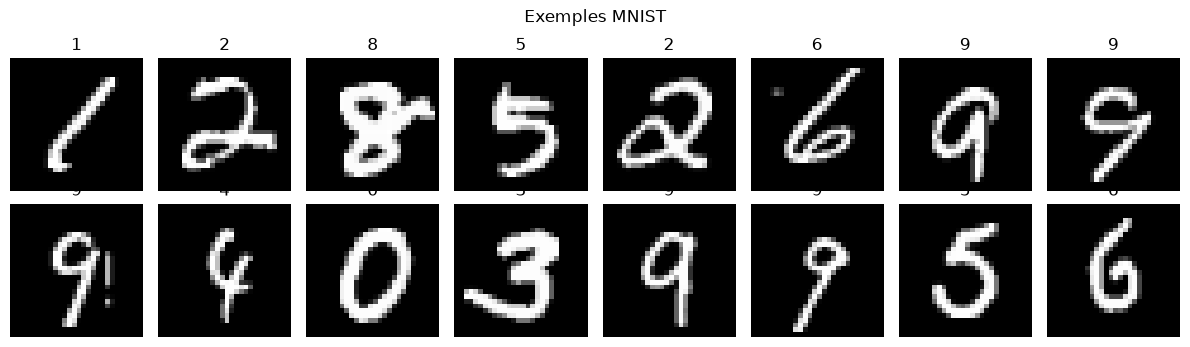

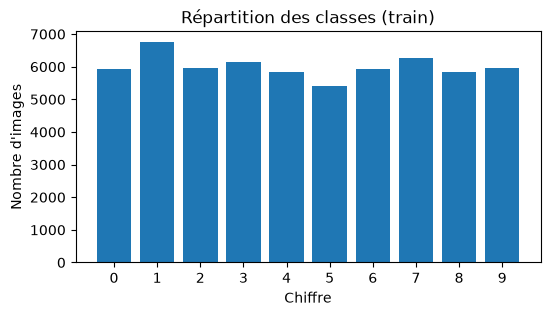

In [3]:
# Visualisation d'un batch
images, labels = next(iter(train_loader))
print("Batch images :", images.shape)   # (B, 1, 28, 28)
print("Batch labels :", labels.shape)
print("Min / Max pixel :", images.min().item(), images.max().item())

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, lbl in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(int(lbl))
    ax.axis("off")
plt.suptitle("Exemples MNIST")
plt.tight_layout()
plt.show()

# Distribution des classes
counts = torch.bincount(train_dataset.targets, minlength=10)
plt.figure(figsize=(6, 3))
plt.bar(range(10), counts.numpy())
plt.xticks(range(10))
plt.xlabel("Chiffre")
plt.ylabel("Nombre d'images")
plt.title("Répartition des classes (train)")
plt.show()